# 새 섹션

In [ ]:
!pip install -q paddlepaddle==3.2.0 -i https://www.paddlepaddle.org.cn/packages/stable/cpu/
!pip install -q paddleocr==3.7.0

Mounted at /content/drive


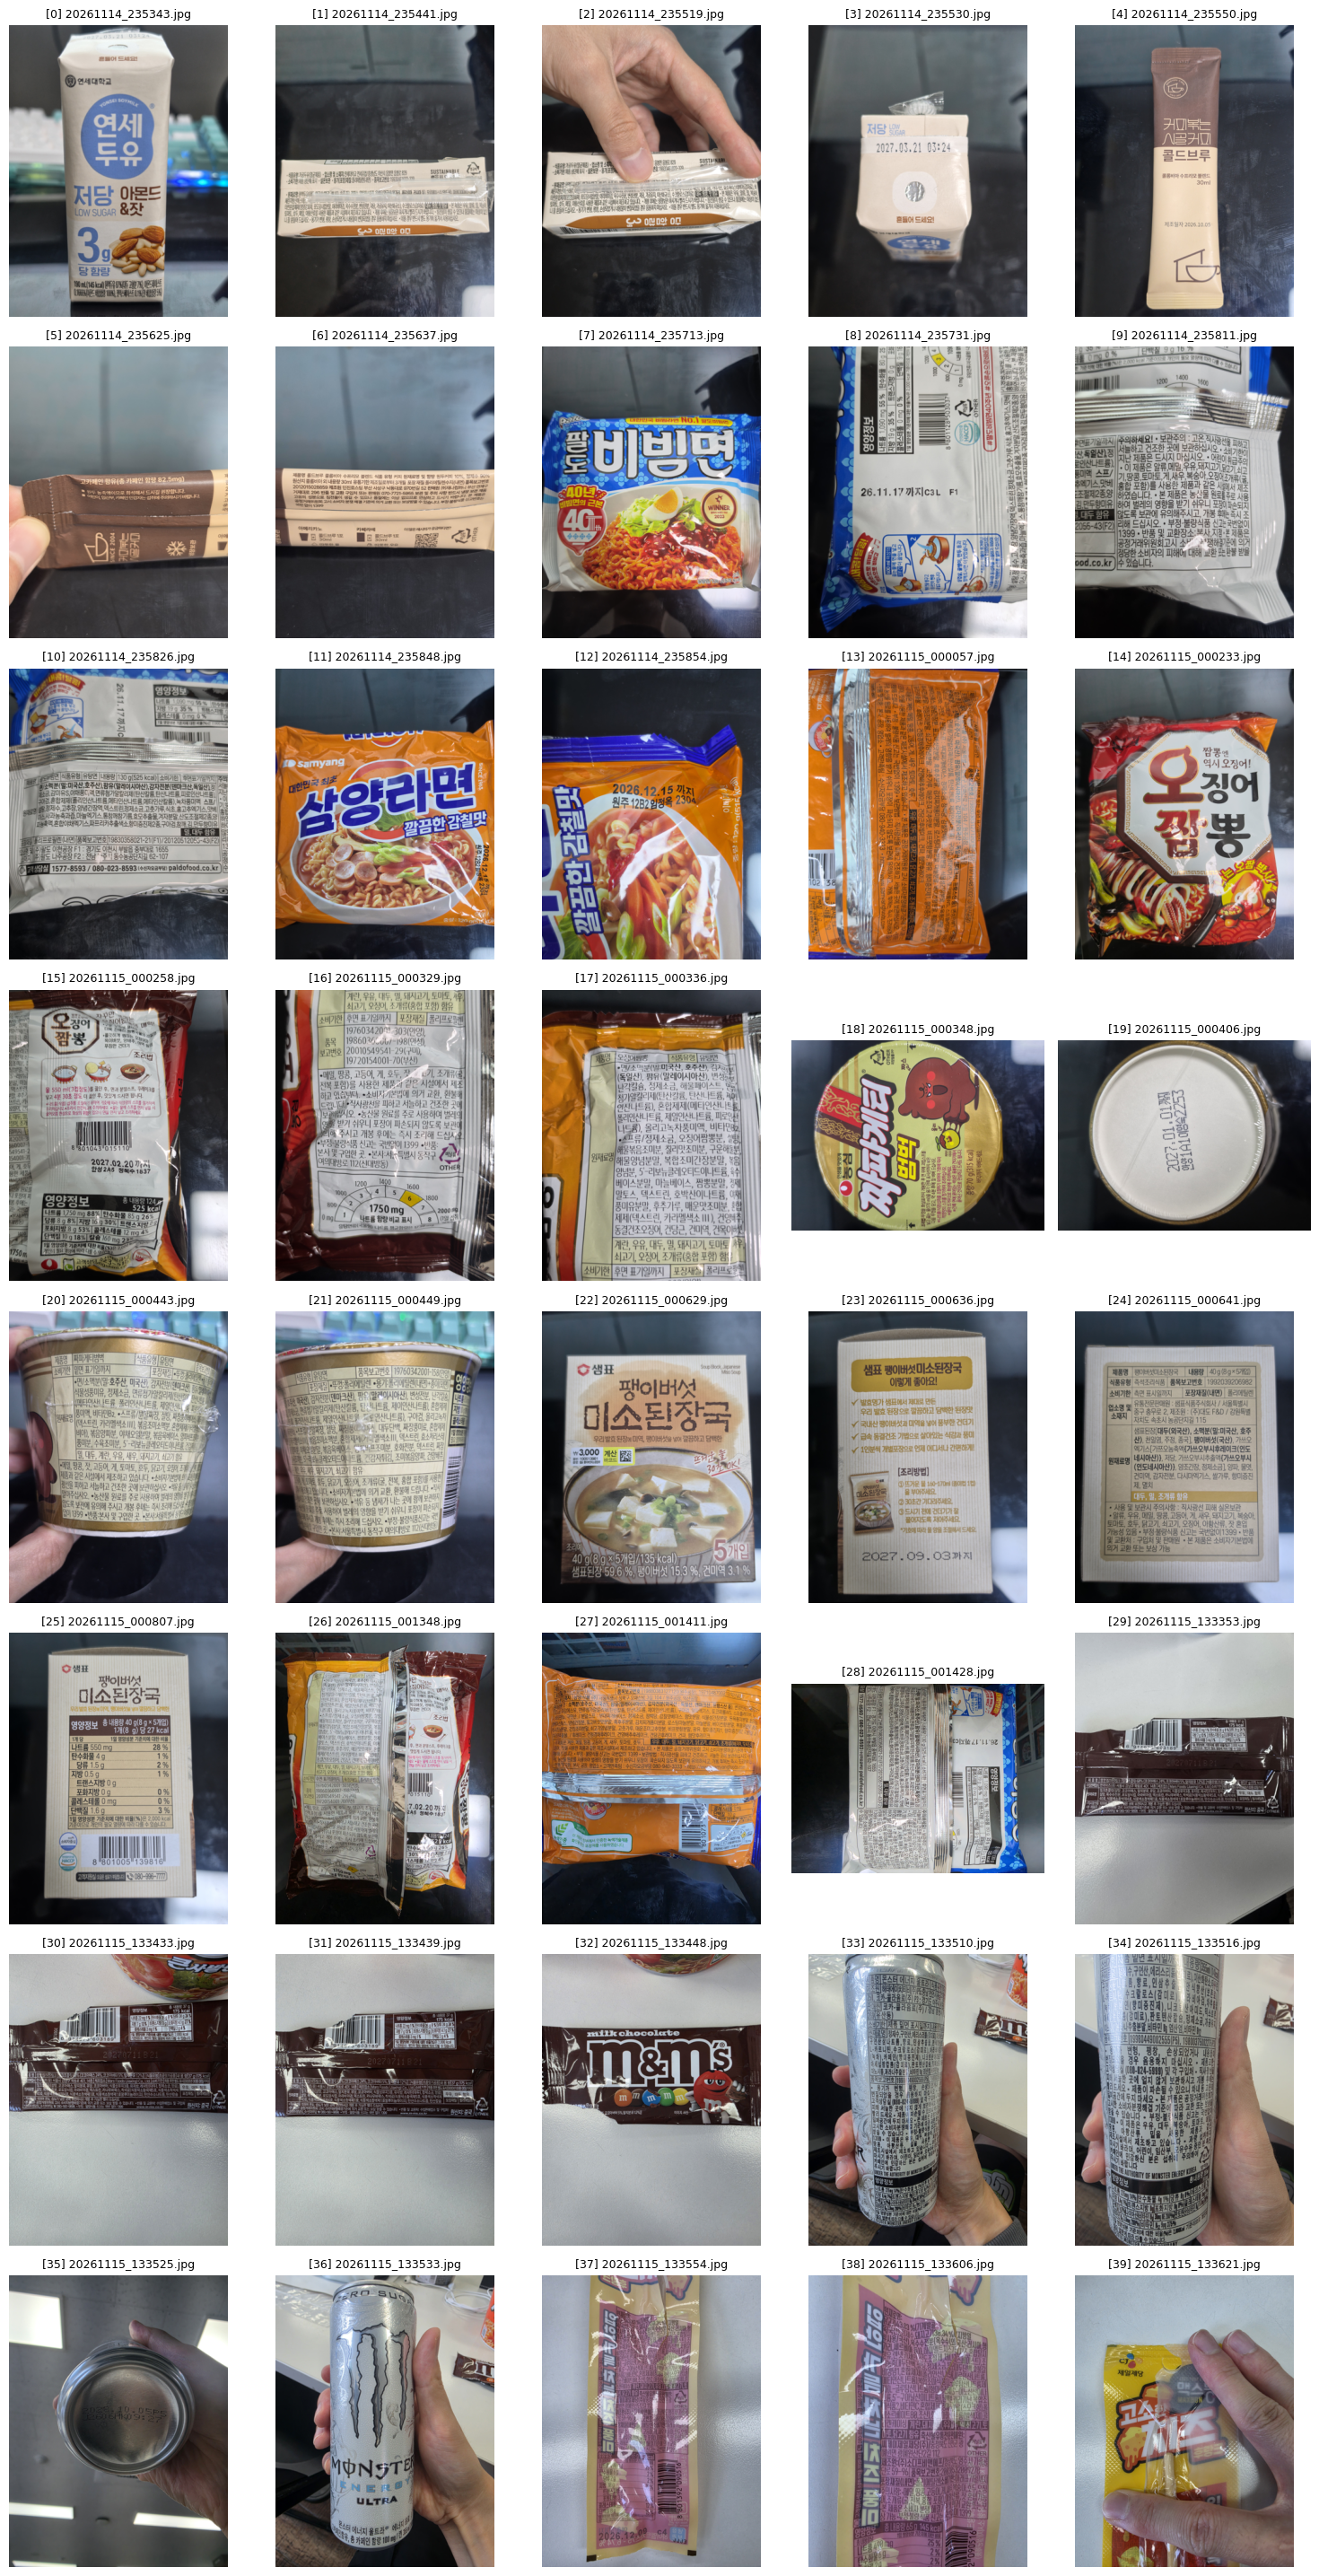

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, math
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

DATA_DIR = '/content/drive/MyDrive/ocr_test/new_data'
files = sorted(f for f in os.listdir(DATA_DIR)
               if f.lower().endswith(('.jpg', '.jpeg', '.png')))

cols = 5
rows = math.ceil(len(files) / cols)
plt.figure(figsize=(cols * 3, rows * 3.6))
for i, f in enumerate(files):
    img = Image.open(os.path.join(DATA_DIR, f))
    img.draft('RGB', (480, 480))
    img = ImageOps.exif_transpose(img)
    img.thumbnail((480, 480))
    ax = plt.subplot(rows, cols, i + 1)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f'[{i}] {f}', fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
import re, pandas as pd

# 제품번호: 그 제품에 해당하는 사진 번호 (연속이면 0-3, 떨어져 있으면 쉼표)
groups = {
    'P001': '0-3',     # 연세두유
    'P002': '4-6',     # 커피볶는 시골커피
    'P003': '7-10, 28',    # 팔도 비빔면
    'P004': '11-13, 27',   # 삼양라면
    'P005': '14-17, 26',   # 오징어 짬뽕
    'P006': '18-21',   # 짜파게티 범벅
    'P007': '22-25',   # 팽이버섯 미소된장
    'P008': '29-32',   # m&m's
    'P009': '33-36',   # 몬스터
    'P010': '37-39',   # 고소한 치즈
}

DO_RENAME = True   # 먼저 False로 계획만 확인 → 맞으면 True로 바꿔 다시 실행

def parse(s):
    out = []
    for part in s.replace(' ', '').split(','):
        if not part:
            continue
        if '-' in part:
            a, b = part.split('-')
            out += list(range(int(a), int(b) + 1))
        else:
            out.append(int(part))
    return out

plan, used = [], {}
for pid, spec in groups.items():
    for idx in parse(spec):
        if idx in used:
            raise ValueError(f'{idx}번 사진이 {used[idx]}와 {pid}에 중복으로 들어 있습니다.')
        if idx >= len(files):
            raise ValueError(f'{idx}번 사진은 없습니다. (0~{len(files)-1})')
        used[idx] = pid
        old = files[idx]
        if re.match(r'^P\d{3}_', old):
            continue                      # 이미 바꾼 파일은 건너뜀
        plan.append((old, f'{pid}_{old}'))

missing = [i for i in range(len(files)) if i not in used]
for old, new in plan:
    print(old, '→', new)
print(f'\n바꿀 파일: {len(plan)}개')
if missing:
    print('아직 제품을 안 정한 사진 번호:', missing)

if DO_RENAME:
    out_dir = '/content/drive/MyDrive/ocr_test/labels'
    os.makedirs(out_dir, exist_ok=True)
    for old, new in plan:
        os.rename(os.path.join(DATA_DIR, old), os.path.join(DATA_DIR, new))
    pd.DataFrame(plan, columns=['old_name', 'new_name']).to_csv(
        os.path.join(out_dir, 'rename_log.csv'), index=False, encoding='utf-8-sig')
    print('이름 변경 완료')
else:
    print('아직 바꾸지 않았습니다. 계획이 맞으면 DO_RENAME = True 로 바꿔 다시 실행하세요.')

20261114_235343.jpg → P001_20261114_235343.jpg
20261114_235441.jpg → P001_20261114_235441.jpg
20261114_235519.jpg → P001_20261114_235519.jpg
20261114_235530.jpg → P001_20261114_235530.jpg
20261114_235550.jpg → P002_20261114_235550.jpg
20261114_235625.jpg → P002_20261114_235625.jpg
20261114_235637.jpg → P002_20261114_235637.jpg
20261114_235713.jpg → P003_20261114_235713.jpg
20261114_235731.jpg → P003_20261114_235731.jpg
20261114_235811.jpg → P003_20261114_235811.jpg
20261114_235826.jpg → P003_20261114_235826.jpg
20261115_001428.jpg → P003_20261115_001428.jpg
20261114_235848.jpg → P004_20261114_235848.jpg
20261114_235854.jpg → P004_20261114_235854.jpg
20261115_000057.jpg → P004_20261115_000057.jpg
20261115_001411.jpg → P004_20261115_001411.jpg
20261115_000233.jpg → P005_20261115_000233.jpg
20261115_000258.jpg → P005_20261115_000258.jpg
20261115_000329.jpg → P005_20261115_000329.jpg
20261115_000336.jpg → P005_20261115_000336.jpg
20261115_001348.jpg → P005_20261115_001348.jpg
20261115_0003

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, re

DATA_DIR = '/content/drive/MyDrive/ocr_test/new_data'   # 사진 폴더
OUT_DIR  = '/content/drive/MyDrive/ocr_test/labels'     # 결과 저장 폴더
os.makedirs(OUT_DIR, exist_ok=True)

files = sorted(f for f in os.listdir(DATA_DIR)
               if f.lower().endswith(('.jpg', '.jpeg', '.png')))
rule = re.compile(r'^P\d{3}_')
products = sorted({f[:4] for f in files if rule.match(f)})
bad = [f for f in files if not rule.match(f)]

print('사진 수:', len(files))
print('제품 수:', len(products), products)
if bad:
    print('이름 규칙(P001_...)에 안 맞는 파일:', bad)
for f in files:
    print(f)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
사진 수: 40
제품 수: 10 ['P001', 'P002', 'P003', 'P004', 'P005', 'P006', 'P007', 'P008', 'P009', 'P010']
P001_20261114_235343.jpg
P001_20261114_235441.jpg
P001_20261114_235519.jpg
P001_20261114_235530.jpg
P002_20261114_235550.jpg
P002_20261114_235625.jpg
P002_20261114_235637.jpg
P003_20261114_235713.jpg
P003_20261114_235731.jpg
P003_20261114_235811.jpg
P003_20261114_235826.jpg
P003_20261115_001428.jpg
P004_20261114_235848.jpg
P004_20261114_235854.jpg
P004_20261115_000057.jpg
P004_20261115_001411.jpg
P005_20261115_000233.jpg
P005_20261115_000258.jpg
P005_20261115_000329.jpg
P005_20261115_000336.jpg
P005_20261115_001348.jpg
P006_20261115_000348.jpg
P006_20261115_000406.jpg
P006_20261115_000443.jpg
P006_20261115_000449.jpg
P007_20261115_000629.jpg
P007_20261115_000636.jpg
P007_20261115_000641.jpg
P007_20261115_000807.jpg
P008_20261115_133353.jpg
P008_20261115_133433.j

In [ ]:
import numpy as np, pandas as pd
from PIL import Image, ImageOps
from paddleocr import PaddleOCR

ocr = PaddleOCR(
    text_detection_model_name='PP-OCRv5_mobile_det',
    text_recognition_model_name='korean_PP-OCRv5_mobile_rec',  # 한국어+영어+숫자
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    text_det_limit_side_len=1600,
    text_det_limit_type='max',
)

rows, empty = [], []
for i, f in enumerate(files, 1):
    img = ImageOps.exif_transpose(Image.open(os.path.join(DATA_DIR, f))).convert('RGB')
    arr = np.ascontiguousarray(np.array(img)[:, :, ::-1])   # 폰 사진 방향 보정 후 전달
    res = ocr.predict(arr)[0]
    texts, scores, polys = res['rec_texts'], res['rec_scores'], res['rec_polys']
    if len(texts) == 0:
        empty.append(f)
    for n, (t, s, p) in enumerate(zip(texts, scores, polys), 1):
        p = np.array(p)
        rows.append({
            'image': f, 'product_id': f.split('_')[0], 'line_no': n,
            'ocr_text': t, 'score': round(float(s), 3),
            'x1': int(p[:, 0].min()), 'y1': int(p[:, 1].min()),
            'x2': int(p[:, 0].max()), 'y2': int(p[:, 1].max()),
        })
    print(f'[{i}/{len(files)}] {f}: {len(texts)}줄')

df = pd.DataFrame(rows)

# 1) OCR 원본 결과 (위치·신뢰도 포함, 매번 새로 저장)
draft_path = os.path.join(OUT_DIR, 'ocr_draft.csv')
df.to_csv(draft_path, index=False, encoding='utf-8-sig')

# 2) 정답지 (이미 있으면 덮어쓰지 않음)
gt_path = os.path.join(OUT_DIR, 'gt.csv')
if os.path.exists(gt_path):
    print('gt.csv가 이미 있어서 건드리지 않았습니다.')
else:
    gt = df[['image', 'product_id', 'line_no', 'ocr_text']].copy()
    gt['gt_text'] = gt['ocr_text']   # 이 열만 고칩니다
    gt['category'] = ''              # 제품명/날짜/알레르기/주의사항/제외
    gt.to_csv(gt_path, index=False, encoding='utf-8-sig')
    print('gt.csv 생성 완료')

print('총 줄 수:', len(df))
if empty:
    print('글자를 하나도 못 찾은 사진:', empty)

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-OCRv5_mobile_det', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-OCRv5_mobile_det), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv5_mobile_det`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Creating model: ('korean_PP-OCRv5_mobile_rec', None, None)
Using official model (korean_PP-OCRv5_mobile_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/korean_PP-OCRv5_mobile_rec`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

[1/40] P001_20261114_235343.jpg: 19줄
[2/40] P001_20261114_235441.jpg: 13줄
[3/40] P001_20261114_235519.jpg: 12줄
[4/40] P001_20261114_235530.jpg: 5줄
[5/40] P002_20261114_235550.jpg: 8줄
[6/40] P002_20261114_235625.jpg: 5줄
[7/40] P002_20261114_235637.jpg: 17줄
[8/40] P003_20261114_235713.jpg: 15줄
[9/40] P003_20261114_235731.jpg: 47줄
[10/40] P003_20261114_235811.jpg: 25줄
[11/40] P003_20261114_235826.jpg: 26줄
[12/40] P003_20261115_001428.jpg: 54줄
[13/40] P004_20261114_235848.jpg: 11줄
[14/40] P004_20261114_235854.jpg: 5줄
[15/40] P004_20261115_000057.jpg: 17줄
[16/40] P004_20261115_001411.jpg: 49줄
[17/40] P005_20261115_000233.jpg: 15줄
[18/40] P005_20261115_000258.jpg: 91줄
[19/40] P005_20261115_000329.jpg: 75줄
[20/40] P005_20261115_000336.jpg: 73줄
[21/40] P005_20261115_001348.jpg: 86줄
[22/40] P006_20261115_000348.jpg: 23줄
[23/40] P006_20261115_000406.jpg: 3줄
[24/40] P006_20261115_000443.jpg: 52줄
[25/40] P006_20261115_000449.jpg: 43줄
[26/40] P007_20261115_000629.jpg: 20줄
[27/40] P007_20261115_0006

In [ ]:
import os, re
import pandas as pd
from PIL import Image, ImageOps, ImageDraw, ImageFont

DATA_DIR = '/content/drive/MyDrive/ocr_test/new_data'
OUT_DIR  = '/content/drive/MyDrive/ocr_test/labels'
PREV_DIR = os.path.join(OUT_DIR, 'preview')
os.makedirs(PREV_DIR, exist_ok=True)

gt_path = os.path.join(OUT_DIR, 'gt.csv')
gt    = pd.read_csv(gt_path, encoding='utf-8-sig', keep_default_na=False)
draft = pd.read_csv(os.path.join(OUT_DIR, 'ocr_draft.csv'), encoding='utf-8-sig', keep_default_na=False)

# ---- 1) 카테고리 자동 추정 ----
DATE_RE = r'(19|20)?\d{2}\s*[.\-/년]\s*\d{1,2}\s*[.\-/월]\s*\d{1,2}'
ALLERGENS = {'계란','난류','알류','우유','메밀','땅콩','대두','밀','고등어','게','새우',
             '돼지고기','복숭아','토마토','아황산류','호두','닭고기','쇠고기','오징어',
             '조개류','잣','굴','전복','홍합'}

def guess(t):
    t = str(t)
    if re.search(DATE_RE, t) or re.search(r'소비기한|유통기한|까지|EXP|BEST', t, re.I):
        return '날짜'
    if re.search(r'알레르기|함유|제조시설|제조하고', t):
        return '알레르기'
    toks = [x for x in re.split(r'[,()\[\]·/:\s]+', t) if x]
    if sum(x in ALLERGENS for x in toks) >= 2:
        return '알레르기'
    if re.search(r'보관|주의|개봉|전자레인지|직사광선|냉장|냉동', t):
        return '주의사항'
    return '제외'

if (gt['category'] == '').all():
    gt['category'] = gt['ocr_text'].apply(guess)
    gt.to_csv(gt_path, index=False, encoding='utf-8-sig')
    print('category 자동 채우기 완료')
else:
    print('이미 category가 채워져 있어서 건드리지 않았습니다.')
print(gt['category'].value_counts())

# ---- 2) 번호 박스 사진 만들기 ----
COLORS = {'날짜': 'red', '알레르기': 'orange', '주의사항': 'blue', '제외': 'gray'}
cat_map = {(r.image, int(r.line_no)): r.category for r in gt.itertuples()}

try:
    font = ImageFont.load_default(size=30)
except TypeError:
    font = ImageFont.load_default()

for f in sorted(draft['image'].unique()):
    img = ImageOps.exif_transpose(Image.open(os.path.join(DATA_DIR, f))).convert('RGB')
    draw = ImageDraw.Draw(img)
    for r in draft[draft['image'] == f].itertuples():
        c = COLORS.get(cat_map.get((f, int(r.line_no)), '제외'), 'gray')
        draw.rectangle([r.x1, r.y1, r.x2, r.y2], outline=c, width=4)
        draw.text((r.x1, max(0, r.y1 - 32)), str(r.line_no), fill=c, font=font)
    img.thumbnail((2000, 2000))
    img.save(os.path.join(PREV_DIR, f), quality=85)
    print('저장:', f)
print('확인용 사진 위치: ocr_test/labels/preview')

category 자동 채우기 완료
category
제외      1184
알레르기      37
날짜        29
주의사항      25
Name: count, dtype: int64
저장: P001_20261114_235343.jpg
저장: P001_20261114_235441.jpg
저장: P001_20261114_235519.jpg
저장: P001_20261114_235530.jpg
저장: P002_20261114_235550.jpg
저장: P002_20261114_235625.jpg
저장: P002_20261114_235637.jpg
저장: P003_20261114_235713.jpg
저장: P003_20261114_235731.jpg
저장: P003_20261114_235811.jpg
저장: P003_20261114_235826.jpg
저장: P003_20261115_001428.jpg
저장: P004_20261114_235848.jpg
저장: P004_20261114_235854.jpg
저장: P004_20261115_000057.jpg
저장: P004_20261115_001411.jpg
저장: P005_20261115_000233.jpg
저장: P005_20261115_000258.jpg
저장: P005_20261115_000329.jpg
저장: P005_20261115_000336.jpg
저장: P005_20261115_001348.jpg
저장: P006_20261115_000348.jpg
저장: P006_20261115_000406.jpg
저장: P006_20261115_000443.jpg
저장: P006_20261115_000449.jpg
저장: P007_20261115_000629.jpg
저장: P007_20261115_000636.jpg
저장: P007_20261115_000641.jpg
저장: P007_20261115_000807.jpg
저장: P008_20261115_133353.jpg
저장: P008_20261115_133433

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, pandas as pd

BASE = '/content/drive/MyDrive/ocr_test'
LABEL_DIR = f'{BASE}/labels'

SPLIT = {
    'P004': 'test', 'P006': 'test', 'P009': 'test',
    'P001': 'val',  'P008': 'val',
    'P002': 'train', 'P003': 'train', 'P005': 'train', 'P007': 'train', 'P010': 'train',
}
pd.DataFrame(sorted(SPLIT.items()), columns=['product_id', 'split']).to_csv(
    f'{LABEL_DIR}/split.csv', index=False, encoding='utf-8-sig')
print(pd.Series(SPLIT).value_counts())
print('split.csv 저장 완료')

Mounted at /content/drive
train    5
test     3
val      2
Name: count, dtype: int64
split.csv 저장 완료


In [2]:
import re, unicodedata
from google.colab import auth
auth.authenticate_user()
import gspread
from google.auth import default
creds, _ = default()
gc = gspread.authorize(creds)

GT_URL = 'https://docs.google.com/spreadsheets/d/1PSRKCB9WLdeXj3y4P3dO5-QXdvX3Az2s2VLVTeatk34/edit?gid=207309119#gid=207309119'
RES_DIR = f'{BASE}/results'
os.makedirs(RES_DIR, exist_ok=True)
TARGET = ['제품명', '날짜', '알레르기', '주의사항']

# ---- 1) gt 시트 읽기 + 백업 ----
vals = gc.open_by_url(GT_URL).sheet1.get_all_values()
header = [h.strip() or f'memo{i}' for i, h in enumerate(vals[0])]
gt = pd.DataFrame(vals[1:], columns=header)
gt = gt[gt['image'].str.strip() != '']
gt.to_csv(f'{LABEL_DIR}/gt_final.csv', index=False, encoding='utf-8-sig')

# ---- 2) OCR 원본 결과 연결 (시트에서 바뀐 ocr_text 대신 원본 사용) ----
draft = pd.read_csv(f'{LABEL_DIR}/ocr_draft.csv', dtype=str,
                    keep_default_na=False, encoding='utf-8-sig')
ocr_map = {(r.image.strip(), r.line_no.strip()): r.ocr_text for r in draft.itertuples()}

def norm_ln(x):
    try:
        return str(int(float(str(x).strip())))
    except ValueError:
        return ''          # 비어 있는 line_no = OCR이 놓친 줄

gt['category'] = gt['category'].str.strip()
odd = sorted(set(gt['category']) - set(TARGET) - {'제외'})
if odd:
    print('⚠ 오타로 보이는 category (점수에서 빠짐):', odd)

rows = gt[gt['category'].isin(TARGET)].copy()
rows['image'] = rows['image'].str.strip()
rows['product_id'] = rows['image'].str[:4].str.upper()
rows['split'] = rows['product_id'].map(SPLIT).fillna('미지정')
rows['ocr'] = [ocr_map.get((im, norm_ln(ln)), '') for im, ln in zip(rows['image'], rows['line_no'])]
rows['gt'] = rows['gt_text']

blank = rows['gt'].str.strip() == ''
if blank.any():
    print(f'⚠ category는 있는데 gt_text가 빈 줄 {blank.sum()}개 (점수에서 빠짐)')
rows = rows[~blank]

# ---- 3) 오류 계산 ----
def clean(s):  # CER은 띄어쓰기를 빼고 계산
    return re.sub(r'\s+', '', unicodedata.normalize('NFC', str(s)))

def words(s):
    return unicodedata.normalize('NFC', str(s)).split()

def lev(a, b):
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i]
        for j, y in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = cur
    return prev[-1]

rows['gt_chars']  = rows['gt'].map(lambda s: len(clean(s)))
rows['char_err']  = [lev(clean(o), clean(g)) for o, g in zip(rows['ocr'], rows['gt'])]
rows['gt_words']  = rows['gt'].map(lambda s: len(words(s)))
rows['word_err']  = [lev(words(o), words(g)) for o, g in zip(rows['ocr'], rows['gt'])]
rows['missed']    = rows['ocr'].str.strip() == ''
rows['exact']     = [clean(o) == clean(g) for o, g in zip(rows['ocr'], rows['gt'])]
rows['digits_ok'] = [re.sub(r'\D', '', o) == re.sub(r'\D', '', g) for o, g in zip(rows['ocr'], rows['gt'])]

def summarize(d):
    return pd.Series({
        '줄 수': len(d),
        '정답 글자 수': int(d['gt_chars'].sum()),
        'CER(%)': round(100 * d['char_err'].sum() / max(d['gt_chars'].sum(), 1), 2),
        'WER(%)': round(100 * d['word_err'].sum() / max(d['gt_words'].sum(), 1), 2),
        '완전일치(%)': round(100 * d['exact'].mean(), 1) if len(d) else 0,
        '놓친 줄': int(d['missed'].sum()),
    })

summary = pd.DataFrame({
    '전체': summarize(rows),
    'test': summarize(rows[rows['split'] == 'test']),
    'val': summarize(rows[rows['split'] == 'val']),
    'train': summarize(rows[rows['split'] == 'train']),
}).T
by_cat  = pd.DataFrame({c: summarize(rows[rows['category'] == c]) for c in TARGET}).T
by_prod = pd.DataFrame({p: summarize(rows[rows['product_id'] == p])
                        for p in sorted(rows['product_id'].unique())}).T
by_prod.insert(0, 'split', by_prod.index.map(SPLIT))

dates = rows[rows['category'] == '날짜']
date_digit_acc = round(100 * dates['digits_ok'].mean(), 1) if len(dates) else 0

# ---- 4) 저장 ----
std = {'image', 'product_id', 'line_no', 'ocr_text', 'gt_text', 'category'}
extra = [c for c in header if c not in std]
line_err = rows[['image', 'product_id', 'split', 'category', 'line_no', 'gt', 'ocr',
                 'gt_chars', 'char_err', 'missed'] + extra].copy()
line_err['line_CER(%)'] = (100 * line_err['char_err'] / line_err['gt_chars'].clip(lower=1)).round(1)
line_err = line_err.sort_values('char_err', ascending=False)

summary.to_csv(f'{RES_DIR}/summary.csv', encoding='utf-8-sig')
by_cat.to_csv(f'{RES_DIR}/by_category.csv', encoding='utf-8-sig')
by_prod.to_csv(f'{RES_DIR}/by_product.csv', encoding='utf-8-sig')
line_err.to_csv(f'{RES_DIR}/line_errors.csv', index=False, encoding='utf-8-sig')

print('=== 전체 / 분할별 ===');  display(summary)
print('=== 카테고리별 ===');     display(by_cat)
print('=== 제품별 ===');         display(by_prod)
print(f'날짜 줄 숫자 완전일치율: {date_digit_acc}%  (날짜 {len(dates)}줄)')
print('=== 가장 많이 틀린 줄 10개 ===')
display(line_err.head(10)[['image', 'category', 'gt', 'ocr', 'char_err']])
print('저장 위치: ocr_test/results')

=== 전체 / 분할별 ===


,줄 수,정답 글자 수,CER(%),WER(%),완전일치(%),놓친 줄
전체,201.0,3249.0,31.12,51.57,49.8,38.0
test,47.0,802.0,29.93,52.66,36.2,10.0
val,28.0,996.0,28.41,57.81,35.7,4.0
train,126.0,1451.0,33.63,46.63,57.9,24.0


=== 카테고리별 ===


,줄 수,정답 글자 수,CER(%),WER(%),완전일치(%),놓친 줄
제품명,43.0,281.0,21.71,31.94,55.8,7.0
날짜,37.0,672.0,22.17,36.23,48.6,5.0
알레르기,78.0,1343.0,43.63,72.41,48.7,17.0
주의사항,43.0,953.0,22.56,42.11,46.5,9.0


=== 제품별 ===


,split,줄 수,정답 글자 수,CER(%),WER(%),완전일치(%),놓친 줄
P001,val,13.0,535.0,44.11,88.98,30.8,1.0
P002,train,11.0,249.0,59.84,60.87,54.5,4.0
P003,train,26.0,423.0,47.52,58.04,38.5,8.0
P004,test,13.0,392.0,22.70,36.47,38.5,3.0
P005,train,57.0,430.0,3.95,16.33,75.4,3.0
P006,test,19.0,237.0,15.61,46.15,52.6,1.0
P007,train,15.0,154.0,1.30,8.00,86.7,0.0
P008,val,15.0,461.0,10.20,21.82,40.0,3.0
P009,test,15.0,173.0,65.90,86.27,13.3,6.0
P010,train,17.0,195.0,61.03,91.89,5.9,9.0


날짜 줄 숫자 완전일치율: 64.9%  (날짜 37줄)
=== 가장 많이 틀린 줄 10개 ===


,image,category,gt,ocr,char_err
44,P001_20261114_235519.jpg,알레르기,"타민혼합제제(영양강화제, 포도당시럽분말, 아라비아검, 옥수수전분, 변성전분, 자당,...",,88
28,P001_20261114_235441.jpg,알레르기,"타민혼합제제(영양강화제, 포도당시럽분말, 아라비아검, 옥수수전분, 변성전분, 자당,...","민 영 , ,수 기가 , 로 무",80
29,P001_20261114_235441.jpg,알레르기,"토마토, 호두, 메밀, 아황산류를 사용한 제품과 같은 시설에서 제조하고 있습니다. ...",메사용품은 하고있니다 는장보하시니다 전수다품질는 이으,54
83,P002_20261114_235637.jpg,주의사항,거제대로 296 반품 및 교환 구입처 또는 판매원 070-7721-5955 보관 및...,,49
82,P002_20261114_235637.jpg,날짜,원산지 콜롬비아 외 내용량 30ml 유통기한 제조일로부터 3개월 포장 재질 폴리에틸...,,49
294,P004_20261115_000057.jpg,알레르기,"우유, 대두, 밀, 돼지고기, 닭고기, 쇠고기, 조개류(바지락, 모시조개) 함유",,36
293,P004_20261115_000057.jpg,알레르기,"오징어, 잣을 사용한제품과 같은 제조시설에서 제조하고 있습니다.",,29
255,P003_20261115_001428.jpg,알레르기,"기, 땅콩, 토마토, 게, 새우, 복숭아, 오징어, 조개류(굴,",,28
172,P003_20261114_235811.jpg,알레르기,"기, 땅콩, 토마토, 게, 새우, 복숭아, 오징어, 조개류(굴,",,28
64,P002_20261114_235625.jpg,주의사항,"어린이, 임산부, 카페인 민감자는 섭취에 주의하시기 바랍니다.",,28


저장 위치: ocr_test/results


In [3]:
from google.colab import drive
drive.mount('/content/drive')
import os, re
import numpy as np, pandas as pd
from PIL import Image, ImageOps

BASE      = '/content/drive/MyDrive/ocr_test'
DATA_DIR  = f'{BASE}/new_data'
LABEL_DIR = f'{BASE}/labels'
RES_DIR   = f'{BASE}/results'
CROP_DIR  = f'{RES_DIR}/error_crops'
os.makedirs(CROP_DIR, exist_ok=True)

le = pd.read_csv(f'{RES_DIR}/line_errors.csv', dtype=str, keep_default_na=False, encoding='utf-8-sig')
le['char_err'] = pd.to_numeric(le['char_err']).astype(int)
le['missed']   = le['missed'].str.lower() == 'true'
digits = lambda s: re.sub(r'\D', '', s)
le['date_wrong'] = (le['category'] == '날짜') & (le['gt'].map(digits) != le['ocr'].map(digits))

# 상위 30개 + 숫자가 틀린 날짜 줄 전부
top = le[le['char_err'] > 0].sort_values('char_err', ascending=False).head(30)
cases = (pd.concat([top, le[le['date_wrong']]])
           .drop_duplicates(subset=['image', 'line_no', 'gt'])
           .sort_values('char_err', ascending=False)
           .reset_index(drop=True))
cases.insert(0, 'rank', range(1, len(cases) + 1))
cases['오류유형'] = np.where(cases['missed'], '미검출', '오인식')

# OCR 박스 위치로 사진 조각 저장
draft = pd.read_csv(f'{LABEL_DIR}/ocr_draft.csv', dtype=str, keep_default_na=False, encoding='utf-8-sig')
box = {(r.image, r.line_no): tuple(int(v) for v in (r.x1, r.y1, r.x2, r.y2)) for r in draft.itertuples()}

def norm_ln(x):
    try:
        return str(int(float(str(x).strip())))
    except ValueError:
        return ''

cases['crop'] = ''
cur_name, cur_img = None, None
for i, r in cases.iterrows():
    key = (r['image'], norm_ln(r['line_no']))
    if key not in box:
        continue                                   # 미검출 줄은 박스가 없음
    if r['image'] != cur_name:
        cur_name = r['image']
        cur_img = ImageOps.exif_transpose(Image.open(os.path.join(DATA_DIR, cur_name))).convert('RGB')
    x1, y1, x2, y2 = box[key]
    m = 25
    crop = cur_img.crop((max(0, x1 - m), max(0, y1 - m),
                         min(cur_img.width, x2 + m), min(cur_img.height, y2 + m)))
    name = f"{r['rank']:02d}_{os.path.splitext(r['image'])[0]}_L{key[1]}.jpg"
    crop.save(os.path.join(CROP_DIR, name), quality=90)
    cases.at[i, 'crop'] = name

known = {'rank', 'image', 'product_id', 'split', 'category', 'line_no', 'gt', 'ocr', 'gt_chars',
         'char_err', 'missed', 'line_CER(%)', 'date_wrong', '오류유형', 'crop'}
memo_cols = [c for c in cases.columns if c not in known]
cases['원인'] = ''
cases['비고'] = ''
out_cols = ['rank', 'image', 'product_id', 'split', 'category', '오류유형', 'gt', 'ocr',
            'char_err', 'line_CER(%)'] + memo_cols + ['crop', '원인', '비고']
cases[out_cols].to_csv(f'{RES_DIR}/error_cases.csv', index=False, encoding='utf-8-sig')

print('분석할 줄 수:', len(cases))
print(cases['오류유형'].value_counts())
print(cases['category'].value_counts())
print('사진 조각:', (cases['crop'] != '').sum(), '개 → results/error_crops')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
분석할 줄 수: 38
오류유형
미검출    25
오인식    13
Name: count, dtype: int64
category
알레르기    17
날짜      13
주의사항     7
제품명      1
Name: count, dtype: int64
사진 조각: 13 개 → results/error_crops


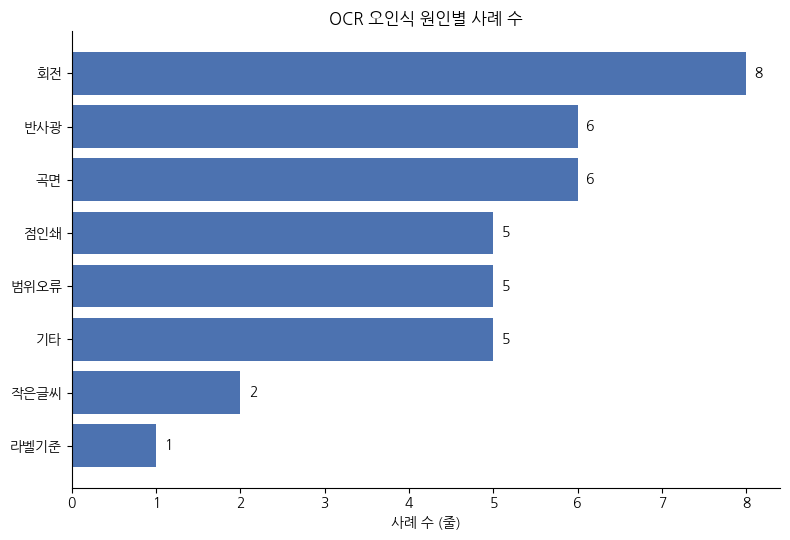

=== 원인별 ===


,사례수,틀린글자수
원인,,
회전,8,342
곡면,6,119
반사광,6,68
기타,5,139
점인쇄,5,35
범위오류,5,112
작은글씨,2,22
라벨기준,1,21


=== 원인 × 카테고리 ===


category,날짜,알레르기,제품명,주의사항
원인,,,,
곡면,0,4,0,2
기타,3,0,0,2
라벨기준,0,0,0,1
반사광,2,4,0,0
범위오류,0,3,0,2
작은글씨,2,0,0,0
점인쇄,5,0,0,0
회전,1,6,1,0


=== 원인 × 오류유형 ===


오류유형,미검출,오인식
원인,,
곡면,5,1
기타,4,1
라벨기준,1,0
반사광,3,3
범위오류,5,0
작은글씨,2,0
점인쇄,0,5
회전,5,3


대표 사례:


,image,category,gt,ocr,원인


In [4]:
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)

from google.colab import auth
auth.authenticate_user()
import gspread
from google.auth import default
gc = gspread.authorize(default()[0])

EC_URL = 'https://docs.google.com/spreadsheets/d/1C4xlTla79pe5nPmqGKkI-zTO9Erl6kwPoVhCnrwtSmA/edit?gid=2059858958#gid=2059858958'

v  = gc.open_by_url(EC_URL).sheet1.get_all_values()
ec = pd.DataFrame(v[1:], columns=[h.strip() or f'col{i}' for i, h in enumerate(v[0])])
ec['char_err'] = pd.to_numeric(ec['char_err'], errors='coerce').fillna(0)
ec = ec[ec['원인'].str.strip() != '']
ec['원인'] = ec['원인'].str.split(r'[,/]')
ec = ec.explode('원인')
ec['원인'] = ec['원인'].str.strip()

by_cause = (ec.groupby('원인')
              .agg(사례수=('image', 'count'), 틀린글자수=('char_err', 'sum'))
              .sort_values('사례수', ascending=False))
by_cause['틀린글자수'] = by_cause['틀린글자수'].astype(int)
cause_x_cat  = pd.crosstab(ec['원인'], ec['category'])
cause_x_type = pd.crosstab(ec['원인'], ec['오류유형'])

by_cause.to_csv(f'{RES_DIR}/error_by_cause.csv', encoding='utf-8-sig')
cause_x_cat.to_csv(f'{RES_DIR}/error_cause_by_category.csv', encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(8, 0.5 * len(by_cause) + 1.5))
s = by_cause['사례수'].sort_values()
ax.barh(s.index, s.values, color='#4C72B0')
for y, val in enumerate(s.values):
    ax.text(val + 0.1, y, str(val), va='center')
ax.set_xlabel('사례 수 (줄)')
ax.set_title('OCR 오인식 원인별 사례 수')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/error_by_cause.png', dpi=200)
plt.show()

print('=== 원인별 ===');            display(by_cause)
print('=== 원인 × 카테고리 ===');    display(cause_x_cat)
print('=== 원인 × 오류유형 ===');    display(cause_x_type)
print('대표 사례:'); display(ec[ec['비고'].str.contains('대표')][['image', 'category', 'gt', 'ocr', '원인']])

In [10]:
!pip install -q paddlepaddle==3.2.0 -i https://www.paddlepaddle.org.cn/packages/stable/cpu/
!pip install -q paddleocr==3.7.0

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
정답 줄 201개, 사진 39장, 원인 연결 38/38줄


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-LCNet_x1_0_doc_ori), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Using official model (PP-LCNet_x1_0_textline_ori), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (7 outputs left out)

[B_방향보정] 1/39 P001_20261114_235343.jpg: 19줄
[B_방향보정] 2/39 P001_20261114_235441.jpg: 13줄
[B_방향보정] 3/39 P001_20261114_235519.jpg: 12줄
[B_방향보정] 4/39 P001_20261114_235530.jpg: 5줄
[B_방향보정] 5/39 P002_20261114_235550.jpg: 8줄
[B_방향보정] 6/39 P002_20261114_235625.jpg: 8줄
[B_방향보정] 7/39 P002_20261114_235637.jpg: 17줄
[B_방향보정] 8/39 P003_20261114_235713.jpg: 13줄
[B_방향보정] 9/39 P003_20261114_235731.jpg: 55줄
[B_방향보정] 10/39 P003_20261114_235811.jpg: 25줄
[B_방향보정] 11/39 P003_20261114_235826.jpg: 26줄
[B_방향보정] 12/39 P003_20261115_001428.jpg: 63줄
[B_방향보정] 13/39 P004_20261114_235848.jpg: 11줄
[B_방향보정] 14/39 P004_20261114_235854.jpg: 3줄
[B_방향보정] 15/39 P004_20261115_000057.jpg: 25줄
[B_방향보정] 16/39 P004_20261115_001411.jpg: 49줄
[B_방향보정] 17/39 P005_20261115_000233.jpg: 11줄
[B_방향보정] 18/39 P005_20261115_000258.jpg: 91줄
[B_방향보정] 19/39 P005_20261115_000329.jpg: 75줄
[B_방향보정] 20/39 P005_20261115_000336.jpg: 73줄
[B_방향보정] 21/39 P005_20261115_001348.jpg: 86줄
[B_방향보정] 22/39 P006_20261115_000348.jpg: 23줄
[B_방향보정] 23/39 P006_202

Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv5_mobile_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv5_mobile_det`.
Creating model: ('korean_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/korean_PP-OCRv5_mobile_rec`.


[C_방향보정+검출강화] 1/39 P001_20261114_235343.jpg: 27줄
[C_방향보정+검출강화] 2/39 P001_20261114_235441.jpg: 19줄
[C_방향보정+검출강화] 3/39 P001_20261114_235519.jpg: 19줄
[C_방향보정+검출강화] 4/39 P001_20261114_235530.jpg: 7줄
[C_방향보정+검출강화] 5/39 P002_20261114_235550.jpg: 11줄
[C_방향보정+검출강화] 6/39 P002_20261114_235625.jpg: 13줄
[C_방향보정+검출강화] 7/39 P002_20261114_235637.jpg: 25줄
[C_방향보정+검출강화] 8/39 P003_20261114_235713.jpg: 34줄
[C_방향보정+검출강화] 9/39 P003_20261114_235731.jpg: 56줄
[C_방향보정+검출강화] 10/39 P003_20261114_235811.jpg: 36줄
[C_방향보정+검출강화] 11/39 P003_20261114_235826.jpg: 49줄
[C_방향보정+검출강화] 12/39 P003_20261115_001428.jpg: 67줄
[C_방향보정+검출강화] 13/39 P004_20261114_235848.jpg: 15줄
[C_방향보정+검출강화] 14/39 P004_20261114_235854.jpg: 12줄
[C_방향보정+검출강화] 15/39 P004_20261115_000057.jpg: 48줄
[C_방향보정+검출강화] 16/39 P004_20261115_001411.jpg: 66줄
[C_방향보정+검출강화] 17/39 P005_20261115_000233.jpg: 24줄
[C_방향보정+검출강화] 18/39 P005_20261115_000258.jpg: 98줄
[C_방향보정+검출강화] 19/39 P005_20261115_000329.jpg: 59줄
[C_방향보정+검출강화] 20/39 P005_20261115_000336.jpg: 47줄
[C_방향보정+검출

,전체 CER,test CER,제품명 CER,날짜 CER,알레르기 CER,주의사항 CER,날짜 숫자일치(%),[회전] 줄 CER,[곡면] 줄 CER,[반사광] 줄 CER,[점인쇄] 줄 CER,[범위오류] 줄 CER
A_기준,27.05,24.94,15.66,18.01,39.17,19.73,21.6,83.74,69.66,24.89,49.15,88.39
B_방향보정,32.78,30.17,25.98,24.70,44.83,23.50,18.9,80.22,70.34,27.00,50.85,78.57
C_방향보정+검출강화,37.80,42.27,22.06,23.07,48.85,37.25,27.0,78.86,83.45,24.89,50.85,50.89


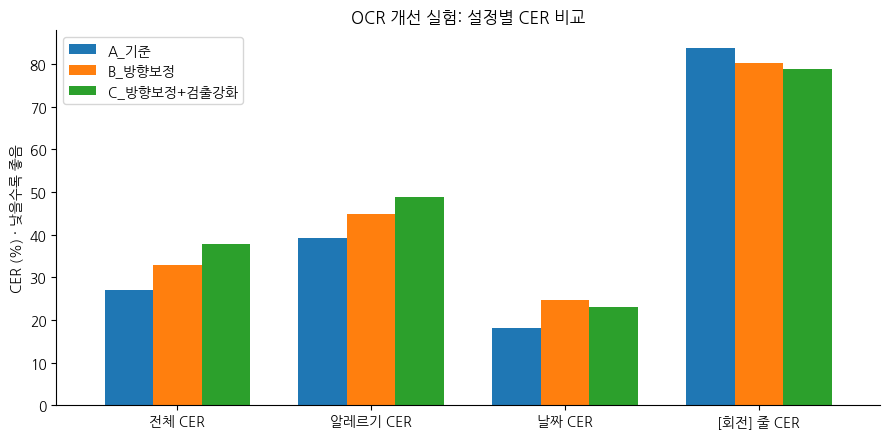

저장: results/improve_compare.csv, results/improve_cer.png, results/experiments/


In [7]:
# ===== 셀 9: OCR 개선 실험 (A 기준 / B 방향보정 / C 방향보정+검출강화) =====
!apt-get -qq install -y fonts-nanum > /dev/null
import os, re, unicodedata
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from PIL import Image, ImageOps
from paddleocr import PaddleOCR
from google.colab import drive, auth
drive.mount('/content/drive')
auth.authenticate_user()
import gspread
from google.auth import default
gc = gspread.authorize(default()[0])

fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family='NanumGothic'); plt.rc('axes', unicode_minus=False)

# ---- 시트 주소 (도현 님 시트) ----
GT_KEY, GT_GID = '1PSRKCB9WLdeXj3y4P3dO5-QXdvX3Az2s2VLVTeatk34', 207309119   # gt
EC_KEY, EC_GID = '1C4xlTla79pe5nPmqGKkI-zTO9Erl6kwPoVhCnrwtSmA', 2059858958  # error_cases

BASE      = '/content/drive/MyDrive/ocr_test'
DATA_DIR  = f'{BASE}/new_data'
LABEL_DIR = f'{BASE}/labels'
RES_DIR   = f'{BASE}/results'
EXP_DIR   = f'{RES_DIR}/experiments'
os.makedirs(EXP_DIR, exist_ok=True)
TARGET = ['제품명', '날짜', '알레르기', '주의사항']
SPLIT = {'P004': 'test', 'P006': 'test', 'P009': 'test', 'P001': 'val', 'P008': 'val',
         'P002': 'train', 'P003': 'train', 'P005': 'train', 'P007': 'train', 'P010': 'train'}

def clean(s):   # 띄어쓰기 빼고 비교
    return re.sub(r'\s+', '', unicodedata.normalize('NFC', str(s)))

# ---- 정답과 원인 불러오기 ----
def sheet_df(key, gid):
    v = gc.open_by_key(key).get_worksheet_by_id(gid).get_all_values()
    return pd.DataFrame(v[1:], columns=[h.strip() or f'col{i}' for i, h in enumerate(v[0])])

gt = sheet_df(GT_KEY, GT_GID)
gt['image'] = gt['image'].str.strip()
gt['category'] = gt['category'].str.strip()
gt = gt[gt['category'].isin(TARGET) & (gt['gt_text'].str.strip() != '')].copy()
gt['split'] = gt['image'].str[:4].map(SPLIT)

ec = sheet_df(EC_KEY, EC_GID)
cause = {(r['image'].strip(), clean(r['gt'])): r['원인'].strip() for _, r in ec.iterrows()}
gt['원인'] = [cause.get((im, clean(g)), '') for im, g in zip(gt['image'], gt['gt_text'])]
images = sorted(gt['image'].unique())
print(f'정답 줄 {len(gt)}개, 사진 {len(images)}장, 원인 연결 {(gt["원인"] != "").sum()}/{len(ec)}줄')

# ---- 실험 설정 ----
COMMON = dict(text_detection_model_name='PP-OCRv5_mobile_det',
              text_recognition_model_name='korean_PP-OCRv5_mobile_rec',
              use_doc_unwarping=False)
CONFIGS = {
    'A_기준': None,   # 기존 ocr_draft.csv 결과 그대로 사용 (다시 돌리지 않음)
    'B_방향보정': dict(use_doc_orientation_classify=True, use_textline_orientation=True,
                     text_det_limit_side_len=1600, text_det_limit_type='max'),
    'C_방향보정+검출강화': dict(use_doc_orientation_classify=True, use_textline_orientation=True,
                          text_det_limit_side_len=2560, text_det_limit_type='max',
                          text_det_thresh=0.2, text_det_box_thresh=0.4),
}

def run_config(name, cfg):
    if cfg is None:
        d = pd.read_csv(f'{LABEL_DIR}/ocr_draft.csv', dtype=str, keep_default_na=False, encoding='utf-8-sig')
        return d.groupby('image')['ocr_text'].apply(list).to_dict()
    path = f'{EXP_DIR}/{name}.csv'
    if os.path.exists(path):
        print(f'{name}: 저장된 결과 사용 (다시 돌리려면 {path} 삭제)')
    else:
        ocr = PaddleOCR(**COMMON, **cfg)
        rows = []
        for i, f in enumerate(images, 1):
            img = ImageOps.exif_transpose(Image.open(os.path.join(DATA_DIR, f))).convert('RGB')
            res = ocr.predict(np.ascontiguousarray(np.array(img)[:, :, ::-1]))[0]
            rows += [{'image': f, 'ocr_text': t, 'score': float(s)}
                     for t, s in zip(res['rec_texts'], res['rec_scores'])]
            print(f'[{name}] {i}/{len(images)} {f}: {len(res["rec_texts"])}줄')
        pd.DataFrame(rows).to_csv(path, index=False, encoding='utf-8-sig')
    d = pd.read_csv(path, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    return d.groupby('image')['ocr_text'].apply(list).to_dict()

# ---- 채점: 정답 줄마다 OCR 결과에서 가장 잘 맞는 줄을 찾아 비교 ----
def sub_lev(g, o):   # g가 o의 어느 부분과 가장 잘 맞는지 (o 앞뒤의 남는 글자는 벌점 없음)
    prev = [0] * (len(o) + 1)
    for i, x in enumerate(g, 1):
        cur = [i]
        for j, y in enumerate(o, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = cur
    return min(prev)

def evaluate(out):
    d = gt.copy()
    errs, best, digit_ok = [], [], []
    for im, g in zip(d['image'], d['gt_text']):
        cg = clean(g)
        cands = [o for o in out.get(im, []) if clean(o)]
        if not cands:
            errs.append(len(cg)); best.append(''); digit_ok.append(False); continue
        scores = [sub_lev(cg, clean(o)) for o in cands]
        k = int(np.argmin(scores))
        errs.append(scores[k]); best.append(cands[k])
        dg = re.sub(r'\D', '', g)
        digit_ok.append(dg != '' and dg in re.sub(r'\D', '', cands[k]))
    d['n'] = d['gt_text'].map(lambda s: len(clean(s)))
    d['err'] = errs
    d['best_ocr'] = best
    d['digit_ok'] = digit_ok
    return d

def cer(x):
    return round(100 * x['err'].sum() / max(x['n'].sum(), 1), 2) if len(x) else None

table = {}
for name, cfg in CONFIGS.items():
    d = evaluate(run_config(name, cfg))
    dates = d[d['category'] == '날짜']
    row = {'전체 CER': cer(d), 'test CER': cer(d[d['split'] == 'test'])}
    for c in TARGET:
        row[f'{c} CER'] = cer(d[d['category'] == c])
    row['날짜 숫자일치(%)'] = round(100 * dates['digit_ok'].mean(), 1)
    for c in ['회전', '곡면', '반사광', '점인쇄', '범위오류']:
        row[f'[{c}] 줄 CER'] = cer(d[d['원인'] == c])
    table[name] = row
    d.to_csv(f'{EXP_DIR}/{name}_lines.csv', index=False, encoding='utf-8-sig')

comp = pd.DataFrame(table).T
comp.to_csv(f'{RES_DIR}/improve_compare.csv', encoding='utf-8-sig')
display(comp)

# ---- 그래프 ----
cols = ['전체 CER', '알레르기 CER', '날짜 CER', '[회전] 줄 CER']
ax = comp[cols].T.plot(kind='bar', figsize=(9, 4.5), rot=0, width=0.75)
ax.set_ylabel('CER (%) · 낮을수록 좋음')
ax.set_title('OCR 개선 실험: 설정별 CER 비교')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/improve_cer.png', dpi=200)
plt.show()
print('저장: results/improve_compare.csv, results/improve_cer.png, results/experiments/')

In [8]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd

RES_DIR = '/content/drive/MyDrive/ocr_test/results'
EXP_DIR = f'{RES_DIR}/experiments'

comp = pd.read_csv(f'{RES_DIR}/improve_compare.csv', index_col=0, encoding='utf-8-sig')
vals = {}
for name in comp.index:
    d = pd.read_csv(f'{EXP_DIR}/{name}_lines.csv', dtype=str, keep_default_na=False, encoding='utf-8-sig')
    d = d[(d['category'] == '날짜') & d['gt_text'].str.contains(r'\d')]   # 숫자가 있는 날짜 줄만
    vals[name] = round(100 * (d['digit_ok'].str.lower() == 'true').mean(), 1)
n = len(d)

comp = comp.drop(columns=['날짜 숫자일치(%)'])
comp[f'날짜 숫자일치(%, 숫자 있는 {n}줄)'] = pd.Series(vals)
comp.to_csv(f'{RES_DIR}/improve_compare.csv', encoding='utf-8-sig')
display(comp)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,전체 CER,test CER,제품명 CER,날짜 CER,알레르기 CER,주의사항 CER,[회전] 줄 CER,[곡면] 줄 CER,[반사광] 줄 CER,[점인쇄] 줄 CER,[범위오류] 줄 CER,"날짜 숫자일치(%, 숫자 있는 21줄)"
A_기준,27.05,24.94,15.66,18.01,39.17,19.73,83.74,69.66,24.89,49.15,88.39,38.1
B_방향보정,32.78,30.17,25.98,24.70,44.83,23.50,80.22,70.34,27.00,50.85,78.57,33.3
C_방향보정+검출강화,37.80,42.27,22.06,23.07,48.85,37.25,78.86,83.45,24.89,50.85,50.89,47.6


In [14]:
import os, sys, json, glob, importlib.util
from google.colab import drive
drive.mount('/content/drive', force_remount=True)   # 드라이브 새로 연결

BASE = '/content/drive/MyDrive/ocr_test'

# ---- ocr_engine.py 찾아서 불러오기 ----
hits = glob.glob(f'{BASE}/**/ocr_engine*.py', recursive=True)
print('찾은 파일:', hits)
if hits:
    path = hits[0]
else:
    from google.colab import files
    print('드라이브에서 못 찾았습니다. 아래 [파일 선택] 버튼으로 PC의 ocr_engine.py를 올려 주세요.')
    up = files.upload()
    path = os.path.join('/content', list(up)[0])

spec = importlib.util.spec_from_file_location('ocr_engine', path)
mod = importlib.util.module_from_spec(spec)
sys.modules['ocr_engine'] = mod
spec.loader.exec_module(mod)
OCREngine = mod.OCREngine
print('불러오기 성공:', path)

# ---- 사진 40장 OCR → JSON 저장 ----
DATA_DIR = f'{BASE}/new_data'
OUT_DIR  = f'{BASE}/results/ocr_json'
os.makedirs(OUT_DIR, exist_ok=True)

engine = OCREngine()
files_ = sorted(f for f in os.listdir(DATA_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
all_results = []
for i, f in enumerate(files_, 1):
    out_path = os.path.join(OUT_DIR, os.path.splitext(f)[0] + '.json')
    r = engine.run_to_json(os.path.join(DATA_DIR, f), out_path)
    all_results.append(r)
    print(f'[{i}/{len(files_)}] {f}: {len(r["lines"])}줄')

with open(f'{BASE}/results/ocr_all.json', 'w', encoding='utf-8') as fp:
    json.dump(all_results, fp, ensure_ascii=False, indent=2)
print('저장: results/ocr_json/ (사진별), results/ocr_all.json (전체)')

Mounted at /content/drive
찾은 파일: ['/content/drive/MyDrive/ocr_test/code/ocr_engine.py']


Creating model: ('PP-OCRv5_mobile_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv5_mobile_det`.


불러오기 성공: /content/drive/MyDrive/ocr_test/code/ocr_engine.py


Creating model: ('korean_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/korean_PP-OCRv5_mobile_rec`.


[1/40] P001_20261114_235343.jpg: 18줄
[2/40] P001_20261114_235441.jpg: 13줄
[3/40] P001_20261114_235519.jpg: 12줄
[4/40] P001_20261114_235530.jpg: 5줄
[5/40] P002_20261114_235550.jpg: 8줄
[6/40] P002_20261114_235625.jpg: 5줄
[7/40] P002_20261114_235637.jpg: 15줄
[8/40] P003_20261114_235713.jpg: 15줄
[9/40] P003_20261114_235731.jpg: 34줄
[10/40] P003_20261114_235811.jpg: 24줄
[11/40] P003_20261114_235826.jpg: 26줄
[12/40] P003_20261115_001428.jpg: 48줄
[13/40] P004_20261114_235848.jpg: 10줄
[14/40] P004_20261114_235854.jpg: 4줄
[15/40] P004_20261115_000057.jpg: 16줄
[16/40] P004_20261115_001411.jpg: 47줄
[17/40] P005_20261115_000233.jpg: 12줄
[18/40] P005_20261115_000258.jpg: 91줄
[19/40] P005_20261115_000329.jpg: 74줄
[20/40] P005_20261115_000336.jpg: 72줄
[21/40] P005_20261115_001348.jpg: 85줄
[22/40] P006_20261115_000348.jpg: 18줄
[23/40] P006_20261115_000406.jpg: 3줄
[24/40] P006_20261115_000443.jpg: 50줄
[25/40] P006_20261115_000449.jpg: 43줄
[26/40] P007_20261115_000629.jpg: 18줄
[27/40] P007_20261115_0006